# Which images does Ramen confuse, and with what? Per-image records on EuroSAT

**Question.** When the zero-shot model or Ramen gets an image wrong, which class does it pick instead? What do
those images look like? And how does one adaptation step change the image's embedding and prediction?

**What this notebook is.** This is a tool for looking at errors, not a test of a new method. Nothing here
changes Ramen. Every image is run through `RamenRecorder` (`src/methods/RamenRecorder.py`). This is Ramen with
one addition: it records four things for each image:

| record | what it is |
|---|---|
| `zs_probs` | zero-shot softmax over the 10 classes, from the pass before adaptation (this pass also decides which memory queue the image is filed in) |
| `probs` | Ramen's softmax, after its one signSGD step on the norm parameters |
| `emb_before` | L2-normalised CLIP image embedding with the pretrained norm parameters (= the zero-shot embedding) |
| `emb_after` | the same embedding with the adapted norm parameters (the one Ramen classifies) |

The `zero_shot → ramen` **outcome** of each image is one of: right → right, *fixed*, *broken*,
wrong → same wrong, wrong → other wrong. The **embedding shift** is 1 − cos(before, after).

The class confusion of each source is a 10 × 10 count matrix: rows are the true class, columns the predicted
class (`confusion.py`). For one class *c* over the N images:
- TP: true *c*, predicted *c*
- FN: true *c*, predicted something else
- FP: true something else, predicted *c*
- TN: everything else

**Data and model.** EuroSAT RGB is a **full run** on all **27,000** Sentinel-2 satellite images (64 × 64) in
**10 land-cover classes**, with one domain. The shift here is from natural photos to satellite images. Model: CLIP
ViT-B/16, prompt "a centered satellite photo of {}.". Ramen config: `cfg/EuroSAT/Ramen.yaml` (capacity 7,500 per
class, top-k 50, β 5, lr 0.01, signSGD). The capacity is larger than the stream, so the memory never evicts.
One shuffled stream, batch size 100. **Seed 0** sets the stream order. Known baseline, seed 0: NoAdapt 48.07 →
Ramen 62.63. Seeds 0–4 give a noise floor of 1.51.

**How the results were produced.**
```
cd new_experiments/2026-10-28_confusion_records
CUDA_VISIBLE_DEVICES=0 nice -n 10 python run_records.py EuroSAT 0     # ~2 min
```
The run is cached under `new_experiments/results/EuroSAT_clip_vitbase16_mixed_nall_bs100_s0_rec_Ramen*`.
Code: `experiment.py` (RecordExperiment), `records.py` (ImageRecords), `confusion.py` (ConfusionMatrix,
ConfusionShift), `gallery.py` (ConfusionGallery), `plots.py`.

**Sanity check (what counts as valid).** The recorder must not change Ramen. Its predictions must equal those of
plain Ramen on the same stream for 100.00% of images (cell 2). The recorded zero-shot prediction is compared with
the separate NoAdapt run for information only. The two use different model wrappers, so fp16 near-ties can flip a
handful of images.

In [1]:
import sys
sys.path.insert(0, '.')
import warnings; warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from experiment import RecordExperiment, count_pct
import plots

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

# ---- settings: change these to look at something else -------------------------------------------------
DATASET, SEED = 'EuroSAT', 0
N_PER_DOMAIN = None                      # None = the whole dataset; an int = that many images per domain
FOCUS_CLASS = 'Herbaceous Vegetation Land'                        # one class to inspect in detail
FOCUS_PAIR = ('Sea or Lake', 'Highway or Road')                          # one (true, predicted) confusion to inspect
OLD_SINK = 'Highway or Road'                              # a class zero-shot over-predicts
NEW_SINK = 'Permanent Crop Land'                              # a class Ramen over-predicts more than zero-shot does

In [2]:
exp = RecordExperiment(DATASET, seed=SEED, n_per_domain=N_PER_DOMAIN).run()   # cached -> no GPU needed
assert exp.sanity_check(), 'the recorder changed Ramen'
records = exp.records
zs, ra = exp.confusion('zero_shot'), exp.confusion('ramen')
shift = exp.shift()
print(f'{len(records):,} images recorded; vectors: ' +
      ', '.join(f'{k} {tuple(v.shape)} {v.dtype}' for k, v in records.arrays.items()))

Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/EuroSAT_clip_vitbase16_mixed_nall_bs100_s0_Ramen.pkl
recorded Ramen prediction == Ramen: 27,000 of 27,000 (100.0%)
NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/EuroSAT_clip_vitbase16_mixed_nall_bs100_s0_NoAdapt.pkl
recorded zero-shot prediction == NoAdapt: 26,907 of 27,000 (99.7%)
27,000 images recorded; vectors: zs_pred (27000,) int32, zs_probs (27000, 10) float16, probs (27000, 10) float16, emb_before (27000, 512) float16, emb_after (27000, 512) float16


## The data

Images and classes present per domain. These are the denominators for everything below. There is one domain, so the outcome table below is split by true class instead of by domain.
With only 10 classes the full confusion matrix is readable, and section 1 shows it.

In [3]:
display(exp.data_table())
support = records.table['label'].value_counts()
print(f'images per class: median {support.median():.0f}, min {support.min()}, max {support.max()}')

,images,classes present
domain,,
satellite,27000,10
all,27000,10


images per class: median 2750, min 2000, max 3000


## Headline: zero-shot vs Ramen

Accuracy per domain, with counts. Below that, each image's outcome from zero-shot to Ramen. The net gain is
*fixed − broken*.

,images,zero-shot correct,Ramen correct,zero-shot %,Ramen %,Δ (pts)
domain,,,,,,
satellite,27000,12984,16910,48.09,62.63,14.54
domain avg,27000,12984,16910,48.09,62.63,14.54


outcome,right -> right,fixed,broken,wrong -> same wrong,wrong -> other wrong
true_class,,,,,
Annual Crop Land,1979,757,56,115,93
Forest,987,1182,61,366,404
Herbaceous Vegetation Land,7,2,193,1671,1127
Highway or Road,1786,512,4,172,26
Industrial Buildings,2009,208,27,250,6
Pasture Land,759,170,316,456,299
Permanent Crop Land,163,332,202,1314,489
Residential Buildings,2867,113,4,16,0
River,1027,418,146,639,270


fixed                  5,008 of 27,000 (18.5%)
broken                 1,082 of 27,000 (4.0%)
wrong -> same wrong    6,137 of 27,000 (22.7%)
wrong -> other wrong   2,871 of 27,000 (10.6%)


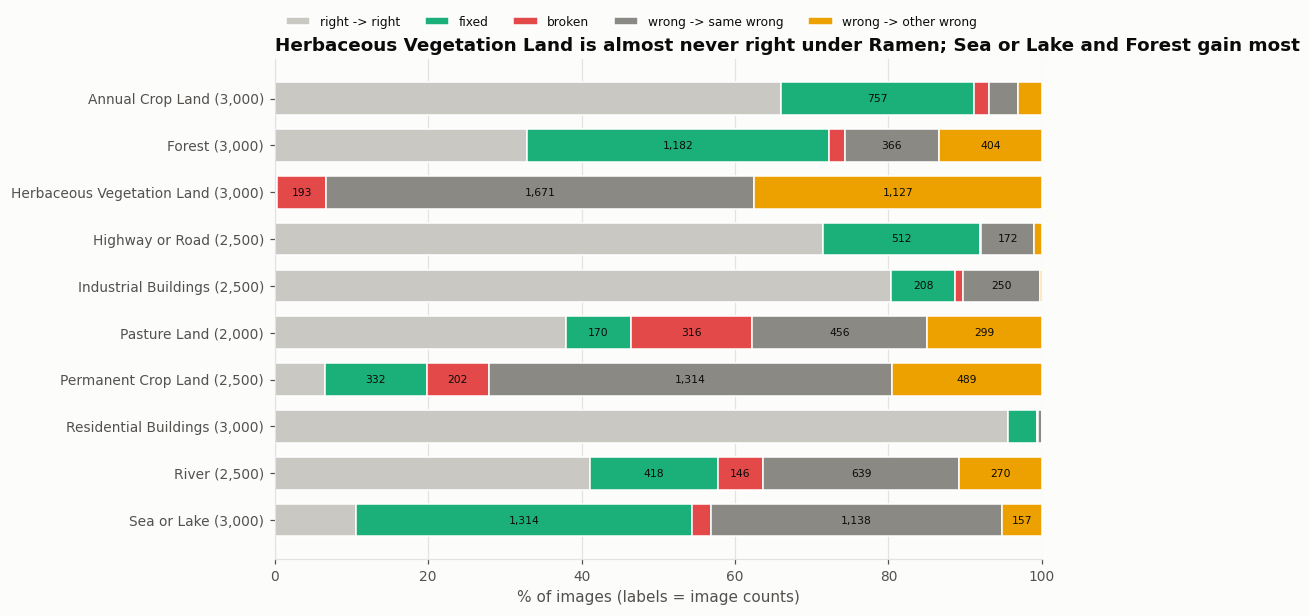

In [4]:
display(exp.accuracy_table())
ot = exp.outcome_table(by='true_class')
display(ot)
n = len(records)
for o in ['fixed', 'broken', 'wrong -> same wrong', 'wrong -> other wrong']:
    print(f'{o:22s} {count_pct(int(ot.loc["all", o]), n)}')
plots.plot_outcomes(ot.drop('all'), title='Herbaceous Vegetation Land is almost never right under Ramen; Sea or Lake and Forest gain most')
plt.show()

## 1. Per-class confusion: TP, FP, FN, TN

`ConfusionMatrix.per_class()` lists every class. The interesting classes are **sinks**: classes predicted far more
often than they occur, which shows up as a large FP. The table below compares zero-shot and Ramen on the classes
whose FP changes most.

In [5]:
print('Full confusion matrices (rows = true class, columns = predicted class):')
for name, cm in [('zero-shot', zs), ('Ramen', ra)]:
    print(name)
    display(cm.to_frame().style.background_gradient(cmap='Blues', axis=None))

Full confusion matrices (rows = true class, columns = predicted class):
zero-shot


predicted,Annual Crop Land,Forest,Herbaceous Vegetation Land,Highway or Road,Industrial Buildings,Pasture Land,Permanent Crop Land,Residential Buildings,River,Sea or Lake
true,,,,,,,,,,
Annual Crop Land,2035,41,58,457,163,44,48,138,2,14
Forest,67,1048,111,1528,16,61,7,6,1,155
Herbaceous Vegetation Land,42,1476,200,590,2,485,63,15,93,34
Highway or Road,153,7,5,1790,225,178,12,122,7,1
Industrial Buildings,12,0,1,3,2036,3,0,445,0,0
Pasture Land,582,77,73,74,31,1075,65,13,3,7
Permanent Crop Land,1179,98,54,102,164,337,365,184,17,0
Residential Buildings,12,51,0,17,41,6,2,2871,0,0
River,170,37,11,558,215,140,36,95,1173,65


Ramen


predicted,Annual Crop Land,Forest,Herbaceous Vegetation Land,Highway or Road,Industrial Buildings,Pasture Land,Permanent Crop Land,Residential Buildings,River,Sea or Lake
true,,,,,,,,,,
Annual Crop Land,2736,9,0,118,28,11,74,8,6,10
Forest,3,2169,8,364,2,195,1,3,25,230
Herbaceous Vegetation Land,40,1497,9,710,3,360,146,112,117,6
Highway or Road,34,0,0,2298,105,8,3,50,2,0
Industrial Buildings,1,0,0,3,2217,0,0,279,0,0
Pasture Land,556,43,3,101,10,929,340,11,6,1
Permanent Crop Land,1272,38,0,165,132,49,495,337,12,0
Residential Buildings,0,1,0,7,12,0,0,2980,0,0
River,74,7,0,724,125,20,43,59,1445,3


In [6]:
pc = shift.per_class()
pc['predicted zero_shot'] = zs.counts.sum(0); pc['predicted ramen'] = ra.counts.sum(0)
cols = ['support', 'predicted zero_shot', 'predicted ramen', 'TP zero_shot', 'TP ramen', 'FP zero_shot', 'FP ramen', 'ΔFP',
        'FN zero_shot', 'FN ramen', 'ΔFN']
print('Classes whose false positives Ramen REMOVES most (zero-shot sinks):')
display(pc.sort_values('ΔFP')[cols].head(5))
print('Classes whose false positives Ramen ADDS most (new sinks):')
display(pc.sort_values('ΔFP', ascending=False)[cols].head(5))

Classes whose false positives Ramen REMOVES most (zero-shot sinks):


,support,predicted zero_shot,predicted ramen,TP zero_shot,TP ramen,FP zero_shot,FP ramen,ΔFP,FN zero_shot,FN ramen,ΔFN
class,,,,,,,,,,,
Highway or Road,2500,7143,5673,1790,2298,5353,3375,-1978,710,202,-508
Pasture Land,2000,2453,1617,1075,929,1378,688,-690,925,1071,146
Annual Crop Land,3000,4640,4754,2035,2736,2605,2018,-587,965,264,-701
Industrial Buildings,2500,2909,2648,2036,2217,873,431,-442,464,283,-181
Herbaceous Vegetation Land,3000,529,21,200,9,329,12,-317,2800,2991,191


Classes whose false positives Ramen ADDS most (new sinks):


,support,predicted zero_shot,predicted ramen,TP zero_shot,TP ramen,FP zero_shot,FP ramen,ΔFP,FN zero_shot,FN ramen,ΔFN
class,,,,,,,,,,,
Permanent Crop Land,2500,602,1103,365,495,237,608,371,2135,2005,-130
River,2500,1308,1690,1173,1445,135,245,110,1327,1055,-272
Sea or Lake,3000,667,1882,391,1632,276,250,-26,2609,1368,-1241
Residential Buildings,3000,3899,3845,2871,2980,1028,865,-163,129,20,-109
Forest,3000,2850,3767,1048,2169,1802,1598,-204,1952,831,-1121


In [7]:
print('Ramen, per class, sorted by FP (TN is large for every class: N minus the rest):')
display(ra.per_class().sort_values('FP', ascending=False).head(10))

Ramen, per class, sorted by FP (TN is large for every class: N minus the rest):


,support,predicted,TP,FP,FN,TN,precision %,recall %,F1 %
class,,,,,,,,,
Highway or Road,2500,5673,2298,3375,202,21125,40.51,91.92,56.23
Annual Crop Land,3000,4754,2736,2018,264,21982,57.55,91.20,70.57
Forest,3000,3767,2169,1598,831,22402,57.58,72.30,64.11
Residential Buildings,3000,3845,2980,865,20,23135,77.50,99.33,87.07
Pasture Land,2000,1617,929,688,1071,24312,57.45,46.45,51.37
Permanent Crop Land,2500,1103,495,608,2005,23892,44.88,19.80,27.48
Industrial Buildings,2500,2648,2217,431,283,24069,83.72,88.68,86.13
Sea or Lake,3000,1882,1632,250,1368,23750,86.72,54.40,66.86
River,2500,1690,1445,245,1055,24255,85.50,57.80,68.97


### Sink fate and sink origin

**Sink fate.** Take the images zero-shot wrongly sends to `OLD_SINK`. Does Ramen fix them, leave them there, or
move them to another wrong class?

**Sink origin.** Take Ramen's false positives of `NEW_SINK`. What did zero-shot predict for them?

In [8]:
fate, moved = exp.sink_fate(OLD_SINK)
display(fate.to_frame(f'{OLD_SINK}: images'))
display(moved.to_frame('images'))
n_fp, origin, domains = exp.sink_origin(NEW_SINK)
print(f'Ramen predicts {NEW_SINK} wrongly for {n_fp:,} images (zero-shot: {int(zs.fp[zs._idx(NEW_SINK)]):,})')
display(origin.to_frame('images')); display(domains.head(6).to_frame('images'))

,Highway or Road: images
zero-shot false positives,5353
fixed by Ramen,2322
still Highway or Road,2287
moved to another wrong class,744


,images
pred_class,
Pasture Land,217
Sea or Lake,171
Forest,157
River,79
Annual Crop Land,56
Permanent Crop Land,44
Industrial Buildings,11
Residential Buildings,8


Ramen predicts Permanent Crop Land wrongly for 608 images (zero-shot: 237)


,images
zs_class,
Annual Crop Land,211
Pasture Land,187
Permanent Crop Land,62
Highway or Road,44
Herbaceous Vegetation Land,35
Forest,31
Industrial Buildings,18
Residential Buildings,14


,images
domain,
satellite,608


## 2. One class in detail

Set `FOCUS_CLASS` in the settings cell. Three views:
1. its TP / FN / FP / TN under both sources;
2. where its images go (`predicted_as`, the row of the matrix);
3. which classes get called by its name (`mistaken_for`, the column).

Then the images themselves. Each caption shows the true class, then the zero-shot prediction with its probability
and the probability of the true class, then the same for Ramen, then the domain and the embedding shift.

zero-shot                Ramen              
                                count     of      %  count     of      %
Herbaceous Vegetation Land                                              
TP (true and predicted)           200   3000   6.67      9   3000    0.3
FN (true, predicted other)       2800   3000  93.33   2991   3000   99.7
FP (other, predicted as it)       329    529  62.19     12     21  57.14
TN (other, predicted other)     23671  24000  98.63  23988  24000  99.95

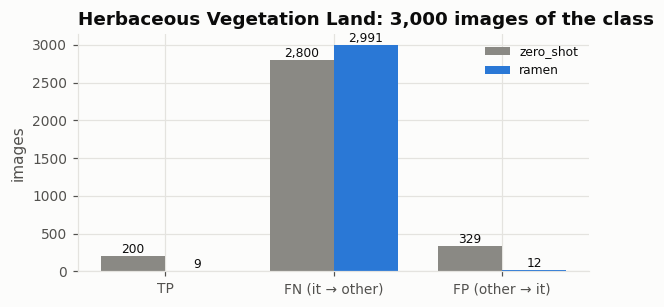

In [9]:
display(pd.concat({'zero-shot': zs.report(FOCUS_CLASS)[['count', 'of', '%']],
                   'Ramen': ra.report(FOCUS_CLASS)[['count', 'of', '%']]}, axis=1))
plots.plot_class_report(shift, FOCUS_CLASS); plt.show()

In [10]:
display(pd.concat({'zero-shot': zs.predicted_as(FOCUS_CLASS, 8).reset_index(),
                   'Ramen': ra.predicted_as(FOCUS_CLASS, 8).reset_index()}, axis=1))
display(pd.concat({'zero-shot': zs.mistaken_for(FOCUS_CLASS, 8).reset_index(),
                   'Ramen': ra.mistaken_for(FOCUS_CLASS, 8).reset_index()}, axis=1))

zero-shot                                                                   Ramen                      
  images of Herbaceous Vegetation Land predicted as count % of its images images of Herbaceous Vegetation Land predicted as count % of its images
0                                            Forest  1476           49.20                                            Forest  1497           49.90
1                                   Highway or Road   590           19.67                                   Highway or Road   710           23.67
2                                      Pasture Land   485           16.17                                      Pasture Land   360           12.00
3                                             River    93            3.10                               Permanent Crop Land   146            4.87
4                               Permanent Crop Land    63            2.10                                             River   117            3.90
5                                  Annual Crop Land    42            1.40                             Residential Buildings   112            3.73
6                                       Sea or Lake    34            1.13                                  Annual Crop Land    40            1.33
7                             Residential Buildings    15            0.50                                       Sea or Lake     6            0.20

zero-shot                                                                                   Ramen                           
  true class of images predicted as Herbaceous Vegetation Land count % of its predictions true class of images predicted as Herbaceous Vegetation Land count % of its predictions
0                                             Forest             111                20.98                                             Forest             8.0                38.10
1                                       Pasture Land              73                13.80                                       Pasture Land             3.0                14.29
2                                   Annual Crop Land              58                10.96                                        Sea or Lake             1.0                 4.76
3                                Permanent Crop Land              54                10.21                                                NaN             NaN                  NaN
4                                        Sea or Lake              16                 3.02                                                NaN             NaN                  NaN
5                                              River              11                 2.08                                                NaN             NaN                  NaN
6                                    Highway or Road               5                 0.95                                                NaN             NaN                  NaN
7                               Industrial Buildings               1                 0.19                                                NaN             NaN                  NaN

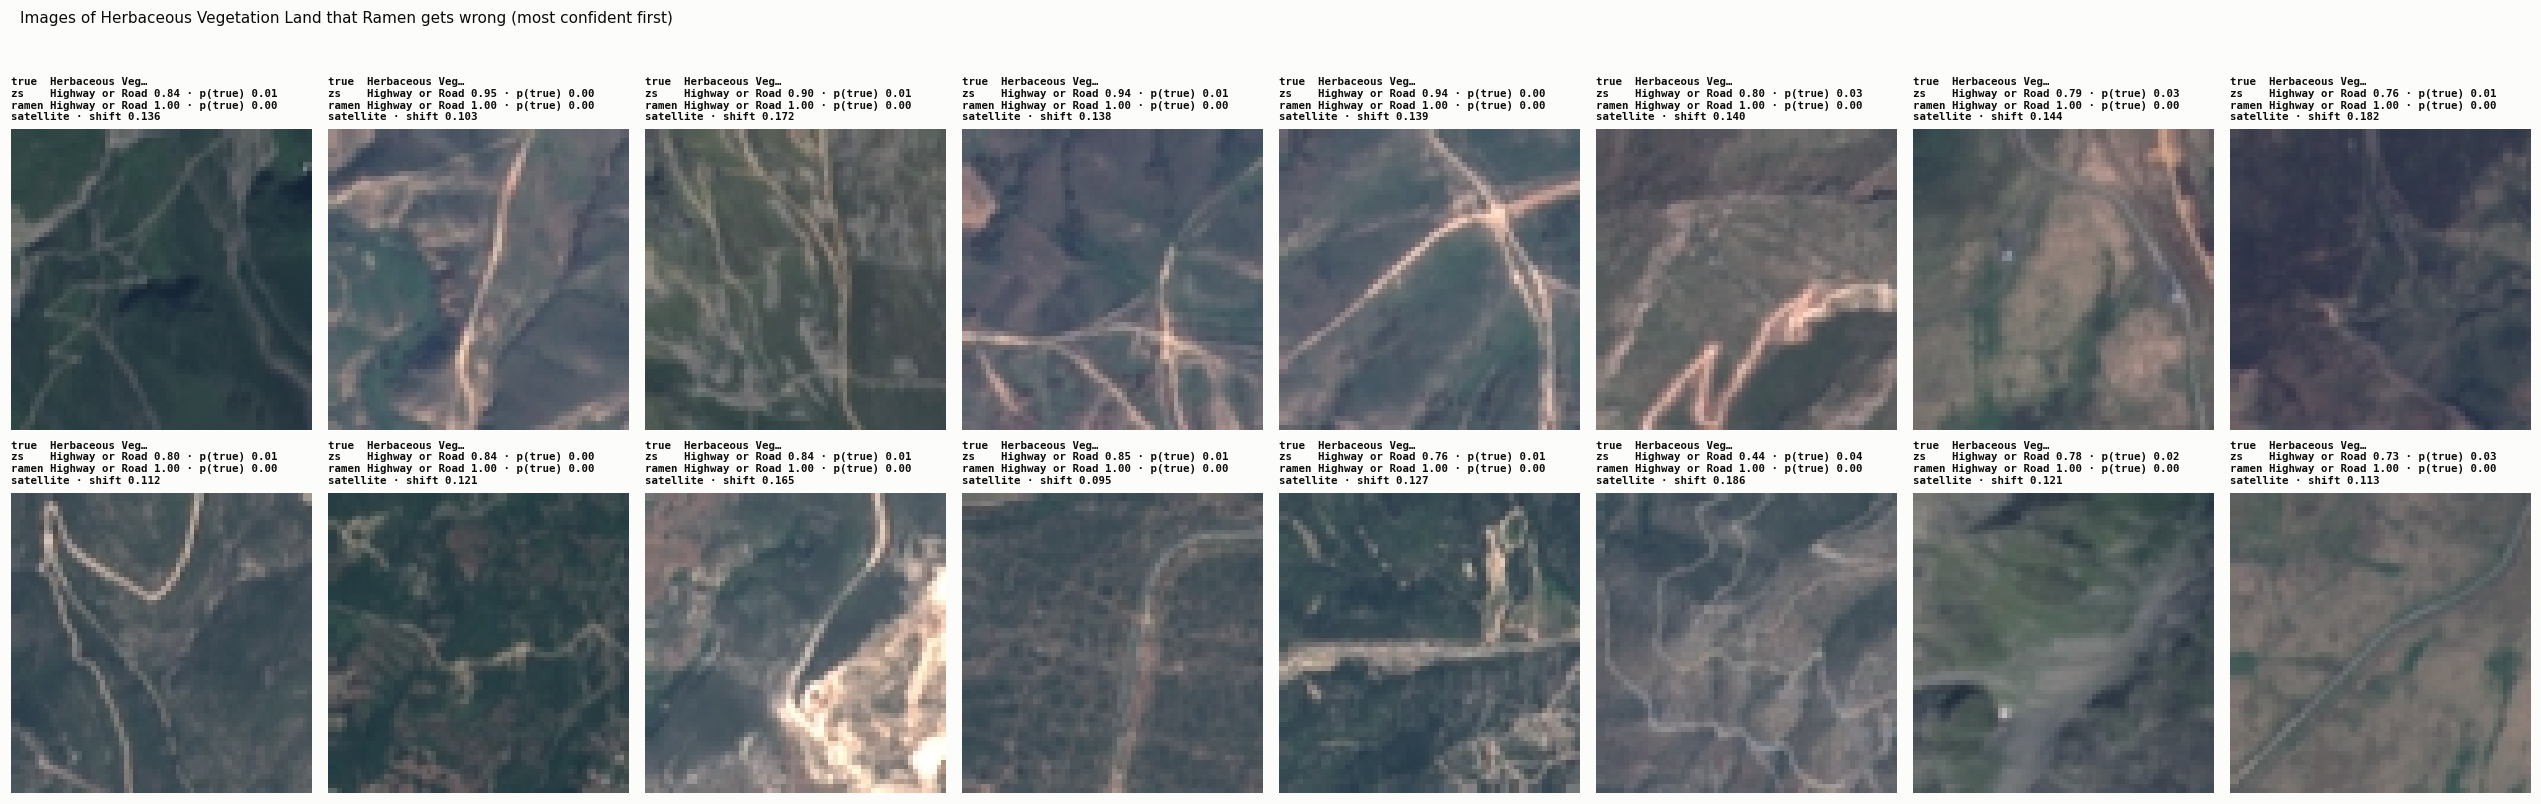

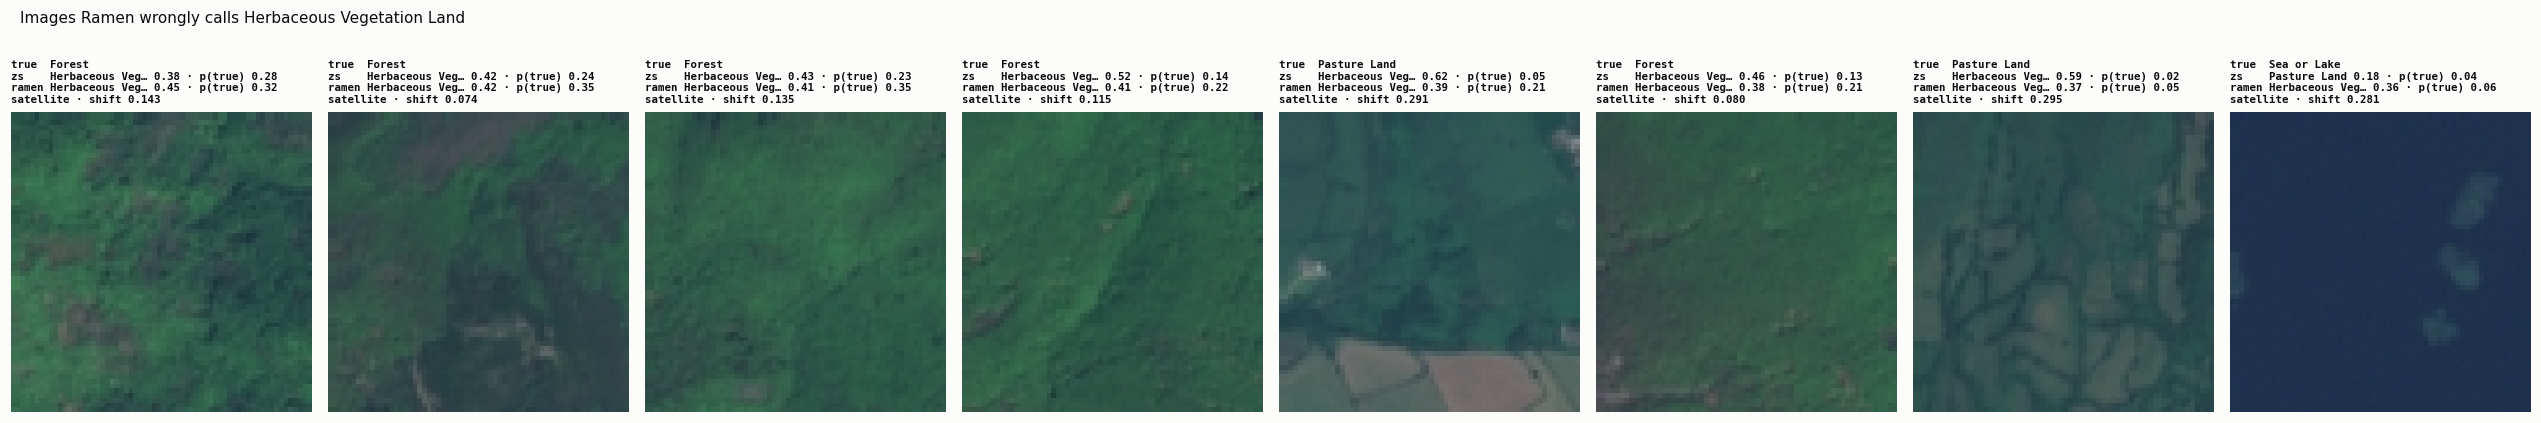

In [11]:
exp.gallery.show(true=FOCUS_CLASS, correct=False, n=16, title=f'Images of {FOCUS_CLASS} that Ramen gets wrong '
                 f'(most confident first)'); plt.show()
exp.gallery.show(pred=FOCUS_CLASS, correct=False, n=8, title=f'Images Ramen wrongly calls {FOCUS_CLASS}'); plt.show()

## 3. Confused pairs

These are the largest off-diagonal cells under each source, then the pairs that change most from zero-shot to Ramen.

In [12]:
display(pd.concat({'zero-shot': zs.top_pairs(12), 'Ramen': ra.top_pairs(12)}, axis=1))

zero-shot                                                                    Ramen                                             
                          true              predicted count % of true class                        true              predicted count % of true class
0                  Sea or Lake        Highway or Road  2024           67.47  Herbaceous Vegetation Land                 Forest  1497           49.90
1                       Forest        Highway or Road  1528           50.93         Permanent Crop Land       Annual Crop Land  1272           50.88
2   Herbaceous Vegetation Land                 Forest  1476           49.20                 Sea or Lake        Highway or Road  1183           39.43
3          Permanent Crop Land       Annual Crop Land  1179           47.16                       River        Highway or Road   724           28.96
4   Herbaceous Vegetation Land        Highway or Road   590           19.67  Herbaceous Vegetation Land        Highway or Road   710           23.67
5                 Pasture Land       Annual Crop Land   582           29.10                Pasture Land       Annual Crop Land   556           27.80
6                        River        Highway or Road   558           22.32                      Forest        Highway or Road   364           12.13
7   Herbaceous Vegetation Land           Pasture Land   485           16.17  Herbaceous Vegetation Land           Pasture Land   360           12.00
8             Annual Crop Land        Highway or Road   457           15.23                Pasture Land    Permanent Crop Land   340           17.00
9         Industrial Buildings  Residential Buildings   445           17.80         Permanent Crop Land  Residential Buildings   337           13.48
10                 Sea or Lake       Annual Crop Land   388           12.93        Industrial Buildings  Residential Buildings   279           11.16
11         Permanent Crop Land           Pasture Land   337           13.48                      Forest            Sea or Lake   230            7.67

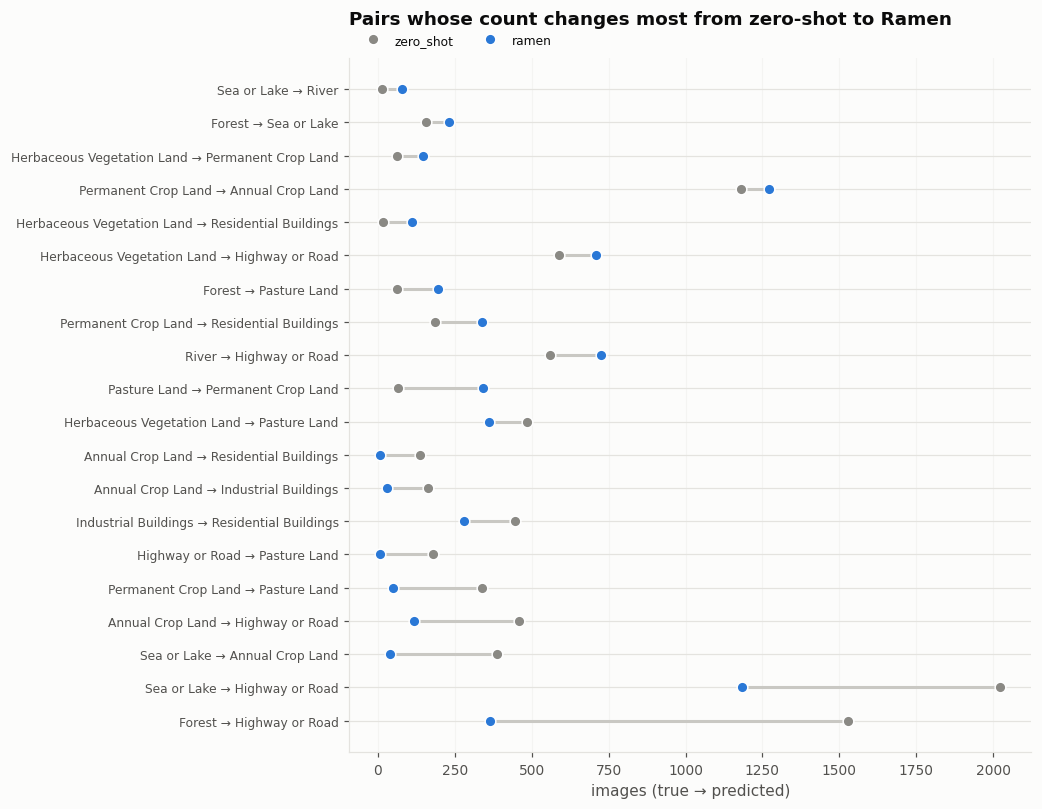

In [13]:
changes = pd.concat([shift.pair_changes(10, 'shrank'), shift.pair_changes(10, 'grew')]).drop_duplicates()
plots.plot_pair_changes(changes.iloc[::-1].reset_index(drop=True), title='Pairs whose count changes most from zero-shot to Ramen'); plt.show()

Sea or Lake -> Highway or Road: zero-shot 2,024, Ramen 1,183 (of 3,000 images of Sea or Lake)


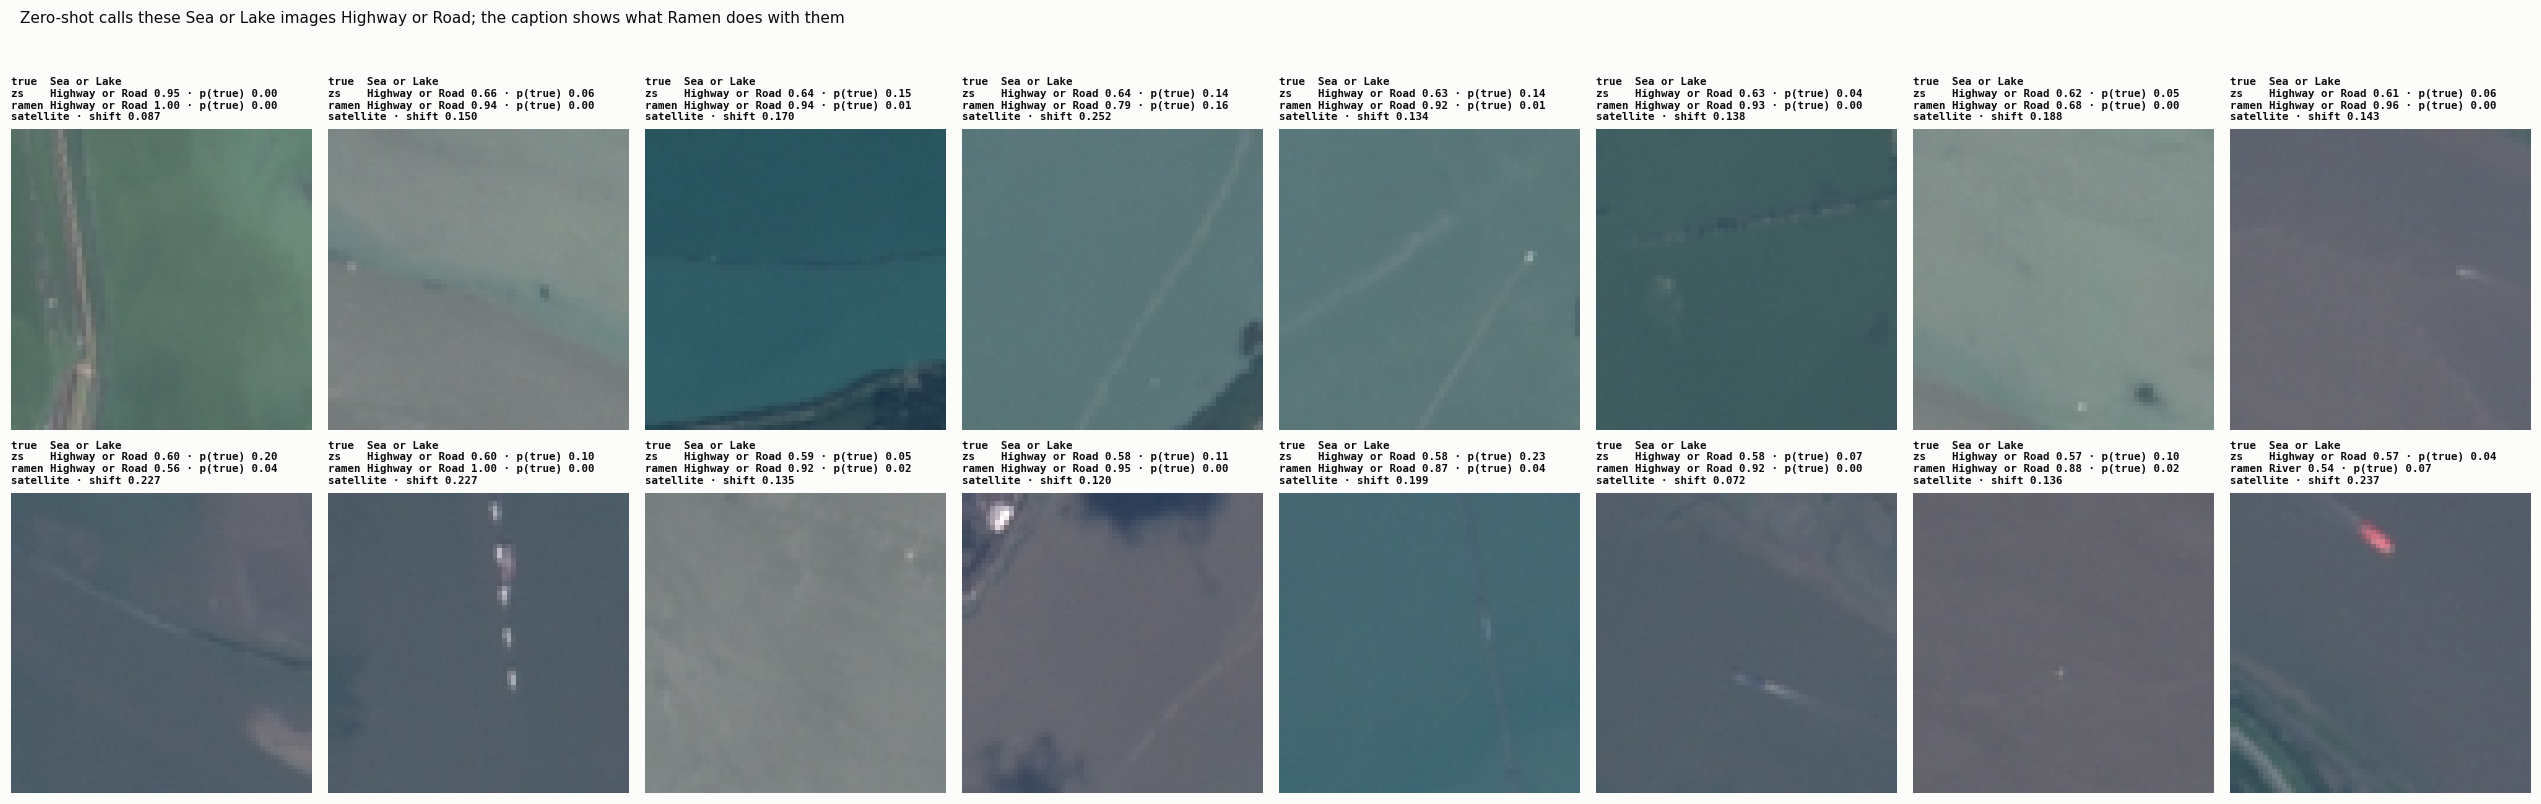

In [14]:
true, pred = FOCUS_PAIR
n_zs, n_ra = zs.pair(true, pred), ra.pair(true, pred)
print(f'{true} -> {pred}: zero-shot {n_zs:,}, Ramen {n_ra:,} (of {int(zs.counts[zs._idx(true)].sum()):,} images of {true})')
exp.gallery.show(true=true, pred=pred, source='zero_shot', n=16, order='confident',
                 title=f'Zero-shot calls these {true} images {pred}; the caption shows what Ramen does with them'); plt.show()

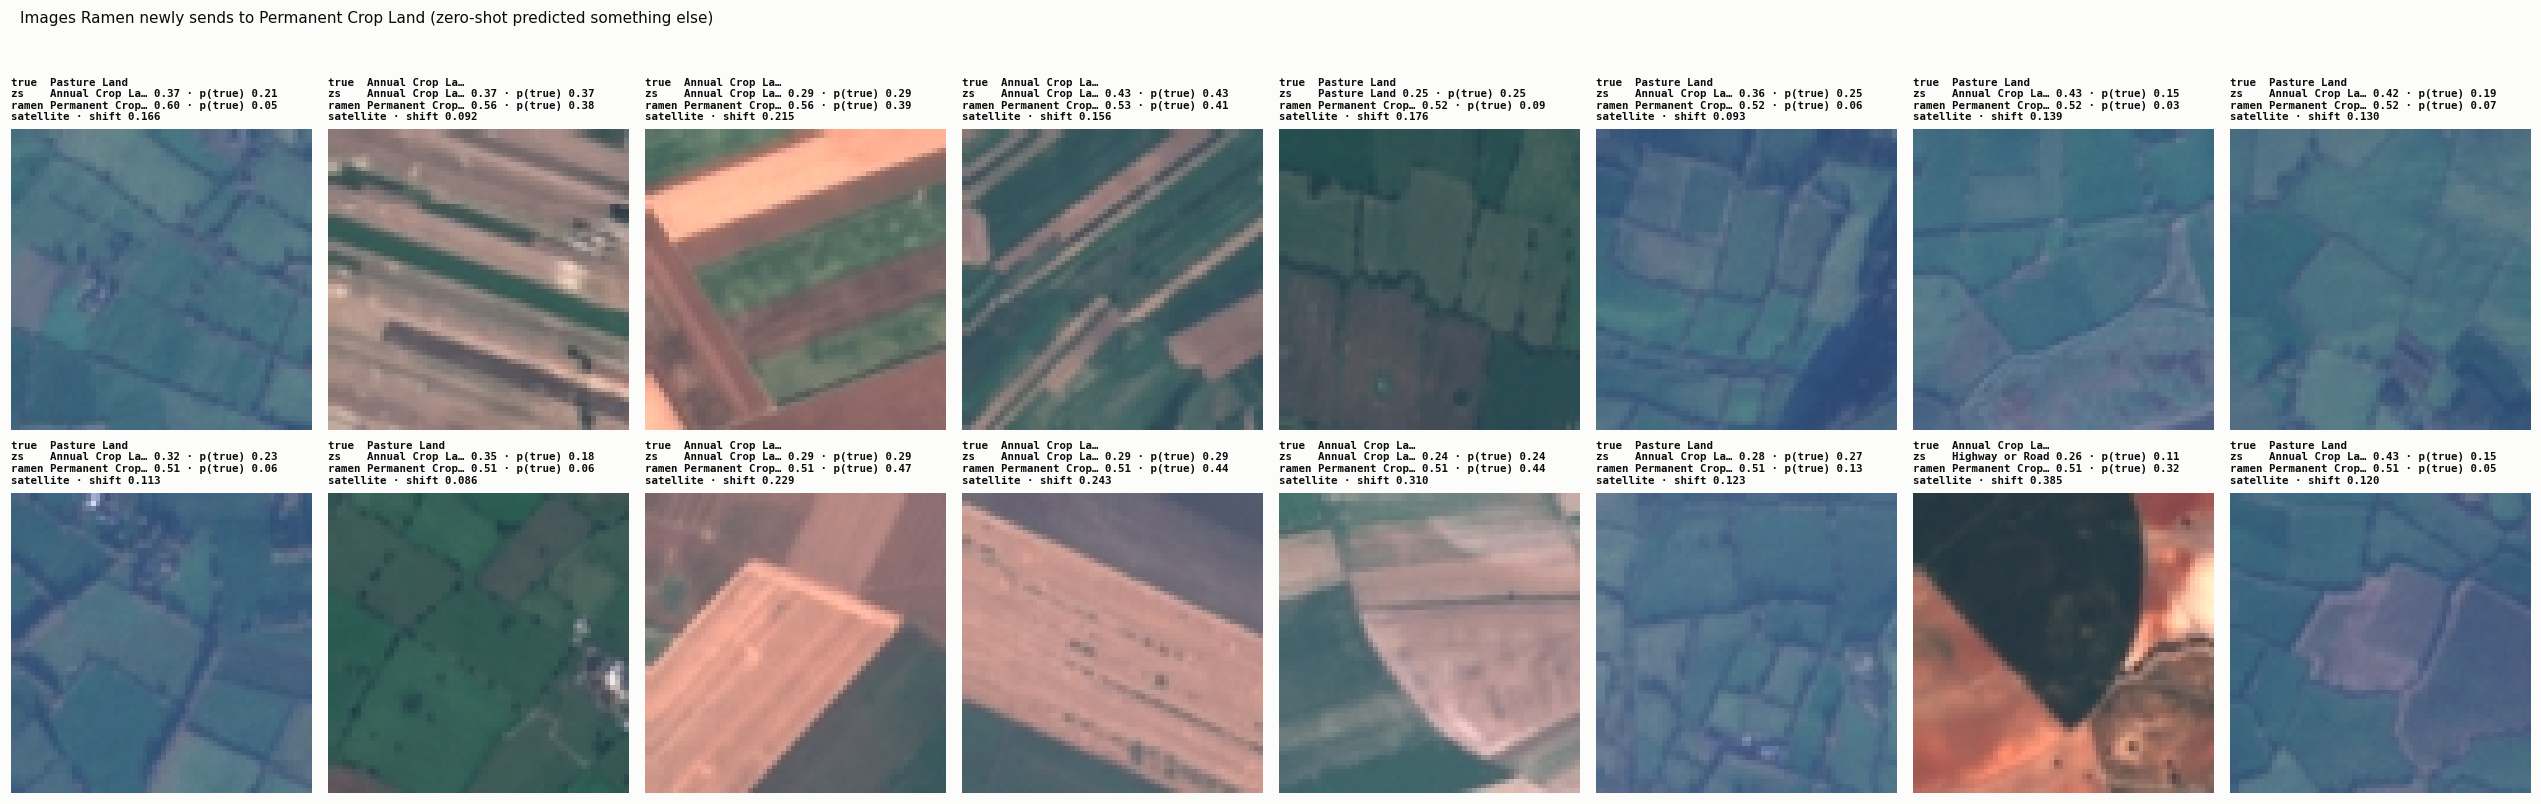

In [15]:
exp.gallery.show(pred=NEW_SINK, correct=False, outcome=['broken', 'wrong -> other wrong'], n=16,
                 title=f'Images Ramen newly sends to {NEW_SINK} (zero-shot predicted something else)'); plt.show()

## 4. Embeddings before and after adaptation

One step on the norm parameters moves each image's embedding a little. The boxes show how far images move, grouped
by outcome. The PCA plot draws an arrow from each image's embedding before adaptation to its embedding after, for
the images of the focus pair's two classes.

,images,median shift,p90 shift,mean shift
outcome,,,,
right -> right,11902,0.14345,0.22527,0.15410
fixed,5008,0.22537,0.34120,0.22708
broken,1082,0.12439,0.24225,0.14502
wrong -> same wrong,6137,0.15113,0.25710,0.16369
wrong -> other wrong,2871,0.18249,0.31378,0.19810


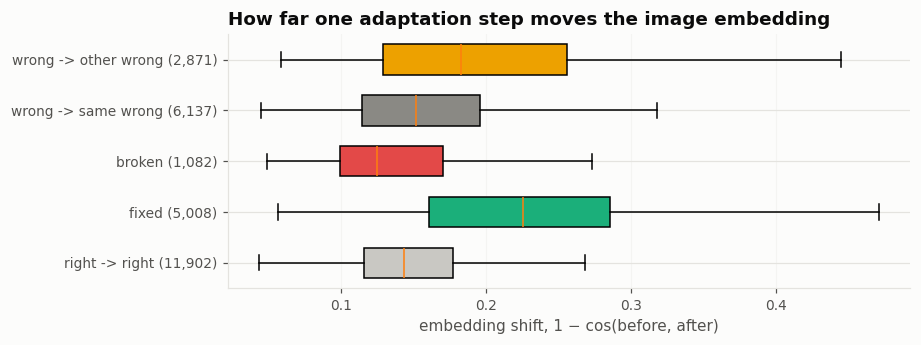

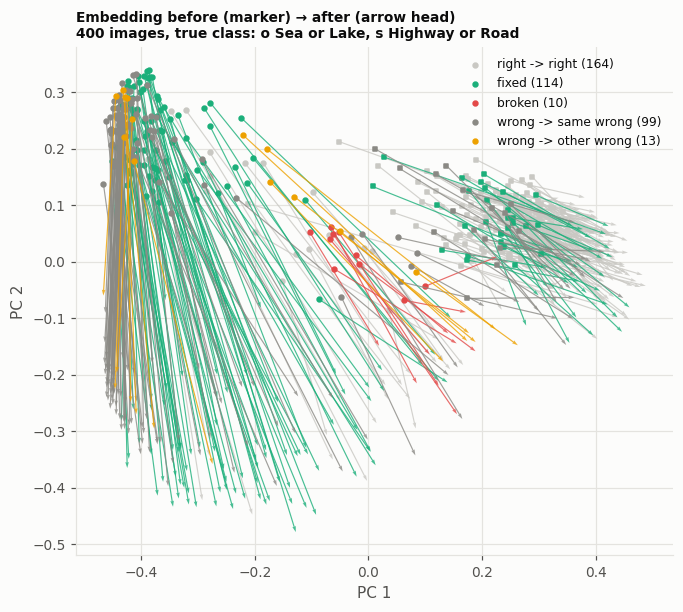

In [16]:
display(exp.embedding_shift_table())
if records.table['domain'].nunique() > 1:
    print('Median shift per domain and outcome (domains move by different amounts, so compare within a row):')
    display(exp.embedding_shift_by_domain())
plots.plot_embedding_shift(records); plt.show()
plots.plot_embedding_moves(records, list(dict.fromkeys(FOCUS_PAIR))); plt.show()

## 5. One image

`gallery.show_image(i)` shows the image with its top classes under zero-shot and under Ramen. The ★ marks the true
class. `records[i]` returns the raw `ImageRecord`, which holds both probability vectors and both embeddings.

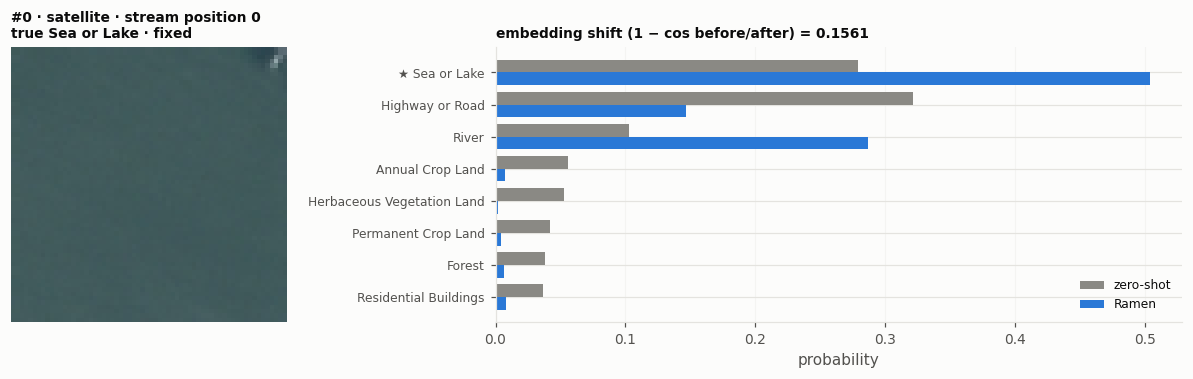

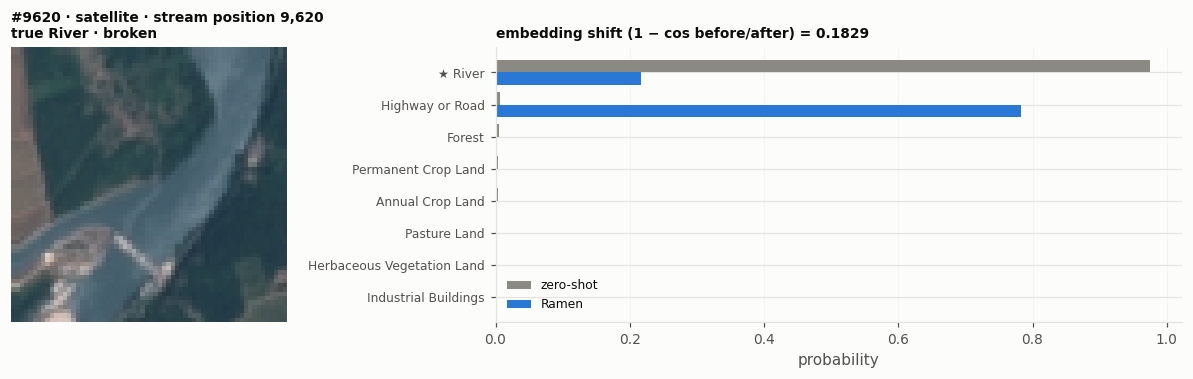

Sea or Lake Highway or Road -> Sea or Lake | emb_before (512,) | top-3 Ramen [('Sea or Lake', 0.50390625), ('River', 0.287109375), ('Highway or Road', 0.1466064453125)]


In [17]:
i = int(records.where(outcome='fixed').index[0])
exp.gallery.show_image(i); plt.show()
j = int(records.where(outcome='broken').sort_values('zs_conf', ascending=False).index[0])
exp.gallery.show_image(j); plt.show()
r = records[i]
print(r.true_class, r.zs_class, '->', r.pred_class, '| emb_before', r.emb_before.shape, '| top-3 Ramen', r.top('ramen', 3, records.classes))

## Interpretation (seed 0, full EuroSAT, 27,000 images)

**On EuroSAT, Ramen really does fix most of what it changes.** Zero-shot gets 12,984 of 27,000 images right (48.09%)
and Ramen gets 16,910 (62.63%). It fixes 5,008 images (18.5%) and breaks 1,082 (4.0%), a net gain of 3,926 images.
Another 2,871 (10.6%) move from one wrong class to another.

**Ramen repairs the main zero-shot sink instead of relocating it, which is the opposite of DomainNet.** Zero-shot
wrongly calls 5,353 images *Highway or Road*. Ramen fixes 2,322 of them (43%), leaves 2,287 at Highway, and moves
744 elsewhere. Its Highway false positives fall to 3,375. On the 12,000-image DomainNet subset, Ramen fixed only
32 of squiggle's 552 false positives.

**What remains is images that do contain a road-like line.** Sea or Lake → Highway falls from 2,024 to 1,183 of
3,000 lake images. The lake images Ramen still calls Highway show a thin linear structure (a boat wake, a trail,
a shoreline), and Ramen raises its confidence in Highway from about 0.6 to 0.9–1.0. Herbaceous Vegetation Land
images with visible dirt tracks go the same way, to Highway at confidence 1.00.

**Herbaceous Vegetation Land was already lost under zero-shot. Ramen removes the last of it.** Zero-shot gets 200
of 3,000 right (6.67%); Ramen gets 9 (0.30%) and predicts the class only 21 times in total. Its images go to Forest
(1,497; zero-shot 1,476) and Highway (710; zero-shot 590). Ramen files every image in the memory queue of its
zero-shot class, so a class with few correct zero-shot predictions has a small, impure queue. Every confident step
then pulls its images toward the classes that dominate.

**The new sink sits inside the crop and pasture group.** Ramen wrongly predicts *Permanent Crop Land* for 608 images,
against 237 for zero-shot. Of those 608, 211 were zero-shot *Annual Crop Land* predictions and 187 were *Pasture
Land*. These are confusions between neighbouring agricultural classes, not unrelated mistakes. They are also
low-confidence. For the 546 images that zero-shot did not call Permanent Crop Land, Ramen's median confidence in
it is 0.37 (90th percentile 0.48), against 0.89 for Ramen's correct predictions. Ramen's remaining Highway false
positives are confident (median 0.63 over 3,375 images). A confidence threshold could catch the crop flips but
not the road ones. Earlier gates failed on Ramen as a whole, so treat this as specific to EuroSAT.

**On EuroSAT, the embedding step is larger and its size does carry signal.** The median shift is 0.225 for fixed
images and 0.143 for images that stay right, against 0.04–0.05 for every outcome on DomainNet. Here, images that
move further are more often fixed. That fits a single-domain stream: the memory never evicts (capacity 7,500 per
class is more than the 27,000-image stream), and every retrieved gradient comes from the same satellite domain.

**Caveats.** Seed 0 only. The gain (+14.54) is far above the 1.51 noise floor, but the per-class numbers are counts
from one stream order.

## Glossary

- **Zero-shot (NoAdapt)**: CLIP classifies by cosine similarity between the image embedding and the text embedding
  of each class name. No adaptation.
- **Ramen**: test-time adaptation. Each image is written into the memory queue of its zero-shot class, together
  with its own entropy gradient. Gradients of the nearest stored images are retrieved, one signSGD step is taken
  on the LayerNorm parameters, the image is predicted, and the parameters are reset.
- **Embedding before / after**: the L2-normalised CLIP image feature with the pretrained / adapted norm parameters.
- **Embedding shift**: 1 − cosine(before, after). 0 means the step did not move the image.
- **TP / FP / FN / TN** (for class *c*): true and predicted *c* / predicted *c* but true other / true *c* but
  predicted other / neither.
- **Precision / recall / F1** (for class *c*): TP / predicted *c*; TP / true *c*; 2TP / (2TP + FP + FN), which is 0
  when TP is 0.
- **Sink**: a class predicted far more often than it occurs (large FP).
- **Sink fate**: what Ramen does with the images zero-shot wrongly sends to a sink. They can be fixed, stay at the
  sink, or move to another wrong class.
- **Sink origin**: for Ramen's false positives of a class, what zero-shot had predicted for them.
- **Outcome**: zero-shot → Ramen correctness of one image. *fixed* = wrong → right; *broken* = right → wrong.
- **Subset (`n_per_domain`)**: a random sample of images per domain, which makes a shorter stream. Ramen's memory
  differs from the full run, so its accuracy is not comparable to the full run.
- **Domain average**: the mean of the per-domain accuracies (the headline convention in this project).